# **Visión por Computadora 1 - Trabajo Práctico 1**



### **Descargar las imágenes**

In [27]:
import os
import gdown

folder = 'data/tp1/'
os.makedirs(folder, exist_ok=True)

download_urls = {
  'img_1' : 'https://drive.google.com/file/d/1LLQGS9316oLEjxX8Ktp_9q58WETjnmgr/view?usp=sharing',
  'img_2' : 'https://drive.google.com/file/d/1yBfaQblL3IdiLKSDI7CKjIk5kAzbyfd_/view?usp=sharing',
  'wp_blue' : 'https://drive.google.com/file/d/16VOrMNKzlYSd14w4BJqwqe16IrgPh8kR/view?usp=sharing',
  'wp_red' :  'https://drive.google.com/file/d/1oCn0J15SKgxjEiLoIi6SQ0YoDdqesDRd/view?usp=sharing',
  'wp_green' :  'https://drive.google.com/file/d/1tMJ89YvuH2cC9v58my--3OfBa1GdjwpD/view?usp=sharing'
}

for img, url in download_urls.items():
  gdown.download(url, os.path.join(folder, img + '.png'), quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1LLQGS9316oLEjxX8Ktp_9q58WETjnmgr
To: /Users/luis/Documents/ceia/b3/VPC1_CEIA/data/tp1/img_1.png
100%|██████████| 1.51k/1.51k [00:00<00:00, 4.25MB/s]
Downloading...
From: https://drive.google.com/uc?id=1yBfaQblL3IdiLKSDI7CKjIk5kAzbyfd_
To: /Users/luis/Documents/ceia/b3/VPC1_CEIA/data/tp1/img_2.png
100%|██████████| 77.0k/77.0k [00:00<00:00, 4.27MB/s]
Downloading...
From: https://drive.google.com/uc?id=16VOrMNKzlYSd14w4BJqwqe16IrgPh8kR
To: /Users/luis/Documents/ceia/b3/VPC1_CEIA/data/tp1/wp_blue.png
100%|██████████| 131k/131k [00:00<00:00, 5.74MB/s]
Downloading...
From: https://drive.google.com/uc?id=1oCn0J15SKgxjEiLoIi6SQ0YoDdqesDRd
To: /Users/luis/Documents/ceia/b3/VPC1_CEIA/data/tp1/wp_red.png
100%|██████████| 726k/726k [00:00<00:00, 9.34MB/s]
Downloading...
From: https://drive.google.com/uc?id=1tMJ89YvuH2cC9v58my--3OfBa1GdjwpD
To: /Users/luis/Documents/ceia/b3/VPC1_CEIA/data/tp1/wp_green.png
100%|██████████| 492k/492k [00:00<00:00, 

# Parte 1 (imágenes en `/white_patch`):
  
  1. Implementar el algoritmo White Patch para librarnos de las diferencias de color de iluminación.
  2. Mostrar los resultados obtenidos y analizar las posibles fallas (si es que las hay) en el caso de White Patch.


#### Imágenes originales 

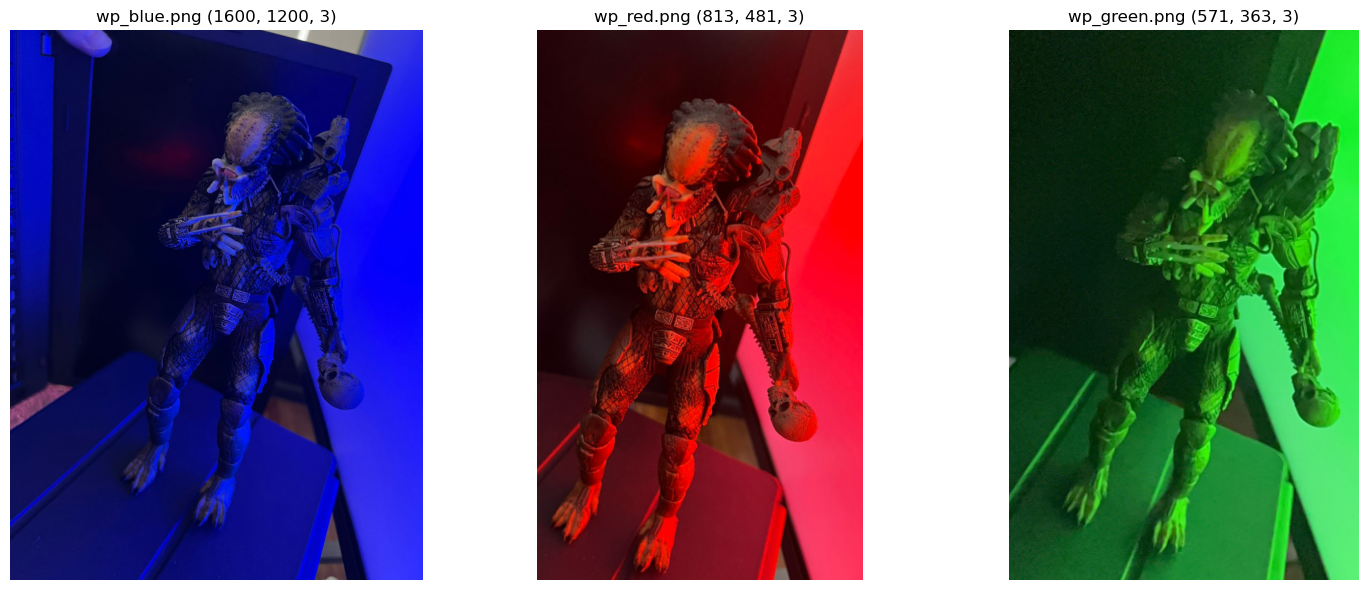

In [28]:
import os
import cv2 as cv
import matplotlib.pyplot as plt

# imágenes de la Parte 1
nombres_wp = ['wp_blue', 'wp_red', 'wp_green']

plt.figure(figsize=(15, 6))

for i, nombre in enumerate(nombres_wp, start=1):
    ruta = os.path.join(folder, nombre + '.png')
    img = cv.imread(ruta)  # OpenCV lee en BGR

    if img is None:
        print(f'No se pudo leer {ruta}')
        continue

    plt.subplot(1, len(nombres_wp), i)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))  # matplotlib espera RGB
    plt.title(f'{nombre}.png {img.shape}')
    plt.axis('off')

plt.tight_layout()
plt.show()

#### Observación previa y motivación

Las tres imágenes son la misma escena con luz azul, roja y verde, así que las diferencias principales se deben a la iluminación.

- En cada una domina un canal (azul en `wp_blue`, rojo en `wp_red`, verde en `wp_green`), y los colores reales de la figura se pierden.
- No hay ningún objeto blanco que podamos usar como referencia.
- Hay zonas muy oscuras (fondo y sombras) con poca información de color. 
- Las imágenes tienen distinta resolución: 1600×1200, 813×481 y 571×363.

#### Algoritmo White Patch

Para compensar la dominante aplicamos **White Patch**:

Asumimos que los valores máximos de color en los tres canales es el color del blanco bajo la luz de la escena:
- $R_{max}(Img)$: Valor máximo del canal R de la imagen
- $G_{max}(Img)$: Valor máximo del canal G de la imagen
- $B_{max}(Img)$: Valor máximo del canal B de la imagen

Normalizamos entonces al color de la luz blanca puro (255, 255, 255):

$$(R,G,B) \rightarrow \left(\frac{255}{R_{max}(Img)}R,\ \frac{255}{G_{max}(Img)}G,\ \frac{255}{B_{max}(Img)}B\right)$$

En este algoritmo, la luz se estima a partir de la propia imagen, sin referencia externa. Como en estas escenas no hay un blanco real, el supuesto puede no cumplirse.

In [29]:
import numpy as np
from numpy import ndarray
import cv2 as cv
import matplotlib.pyplot as plt

def white_patch_algorithm(R_white: ndarray, G_white: ndarray, B_white: ndarray, percentile = 95) -> ndarray:
  
  # Me quedo con los maximos
  R_max = np.max(R_white)
  G_max = np.max(G_white)
  B_max = np.max(B_white)

  # Si el máximo llegó a 255 (reflejos/píxeles quemados), usamos el percentil 95
  if R_max == 255:
    R_max = np.percentile(R_white, percentile)

  if G_max == 255:
    G_max = np.percentile(G_white, percentile)

  if B_max == 255:
    B_max = np.percentile(B_white, percentile)

  # Evitamos división por cero si algún máximo fuera 0
  R_max = max(R_max, 1)
  G_max = max(G_max, 1)
  B_max = max(B_max, 1)

  # https://numpy.org/doc/stable/reference/generated/numpy.clip.html
  # controlamos los rangos para evitar desbordamientos
  R = np.clip(255 * (R_white / R_max), 0, 255)
  G = np.clip(255 * (G_white / G_max), 0, 255)
  B = np.clip(255 * (B_white / B_max), 0, 255)

  return np.array([R, G, B]).astype(np.uint8)

def plot_imgs(img_rgb, img_corrected):

  plt.figure(figsize=(12, 6))

  plt.subplot(1, 2, 1)
  plt.imshow(img_rgb)
  plt.title(f'Imagen Original (RGB)')
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(img_corrected)
  plt.title('Imagen Corregida (White Patch)')
  plt.axis('off')

  plt.show()

def process_image(image_path: str, plot = True, percentile = 95):
  # Por defecto leo en BRG
  image: ndarray = cv.imread(image_path)

  if image is None:
    raise FileNotFoundError(f"No se pudo cargar la imagen en: {image_path}")

  # Paso la imagen de BRG a RGB
  img_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

  # Me quedo con cada canal por separado
  R_channel = img_rgb[:, :, 0]
  G_channel = img_rgb[:, :, 1]
  B_channel = img_rgb[:, :, 2]

  # Corrijo con white patch
  corrected_channels = white_patch_algorithm(R_channel, G_channel, B_channel, percentile)

  # https://numpy.org/doc/stable/reference/generated/numpy.stack.html
  # El algoritmo devuelve los canales [R, G, B]
  # los transponemos de vuelta a la forma (H, W, C)
  img_corrected = np.stack(corrected_channels, axis=-1)

  if plot: 
    plot_imgs(img_rgb, img_corrected)

  #return img_rgb, img_corrected

Antes de procesar las imagenes con el algoritmo white patch, averiguamos para cada imagen su nivel de saturacion calculando para cada canal (RGB):
- Su valor maximo
- Cuantil percentil 95
- Cuantil percentil 90
- Porcentaje promedio de pixeles saturados (valor 255) 

In [40]:
for nombre in ['wp_blue', 'wp_red', 'wp_green']:
    img = cv.cvtColor(cv.imread(os.path.join(folder, nombre + '.png')), cv.COLOR_BGR2RGB)
    print(f'{nombre}:')
    for c, canal in enumerate('RGB'):
        ch = img[:, :, c]
        print(f'\t - {canal}: max={ch.max()} | p95={np.percentile(ch, 95):.0f} | p90={np.percentile(ch, 90):.0f} | En 255: {(ch == 255).mean() * 100:.2f}%')
    print('-'*50)

wp_blue:
	 - R: max=255 | p95=56 | p90=44 | En 255: 0.00%
	 - G: max=255 | p95=51 | p90=41 | En 255: 0.00%
	 - B: max=255 | p95=252 | p90=245 | En 255: 0.51%
--------------------------------------------------
wp_red:
	 - R: max=255 | p95=255 | p90=253 | En 255: 6.46%
	 - G: max=134 | p95=58 | p90=49 | En 255: 0.00%
	 - B: max=122 | p95=90 | p90=65 | En 255: 0.00%
--------------------------------------------------
wp_green:
	 - R: max=126 | p95=80 | p90=64 | En 255: 0.00%
	 - G: max=252 | p95=237 | p90=233 | En 255: 0.00%
	 - B: max=155 | p95=113 | p90=80 | En 255: 0.00%
--------------------------------------------------


Observamos que:

- La imagen `wp_blue` 
    - Se encuentra saturada por el canal `B`
    - El máximo de los canales `R` y `G` lo definen unos pocos píxeles aislados.
- La imagen `wp_red` 
    - Esta fuertemente saturada en el canal `R`, al punto de que el cuantil percentil 95 no servira para el algoritmo White Patch. Usamos el cuantil percentil 90 para esta imagen
    - Los maximos de canales `G` y `B` lo definen unos pocos píxeles aislados
- La imagen `wp_green` 
    - Se encuentra saturada en el canal `G`
    - Los maximos de canales `R` y `B` lo definen unos pocos píxeles aislados

Para que el algoritmo pueda hacer efecto, cuando el valor maximo de un canal sea 255, se reemplaza por el cuantil apropiado que ignora los píxeles más brillantes.

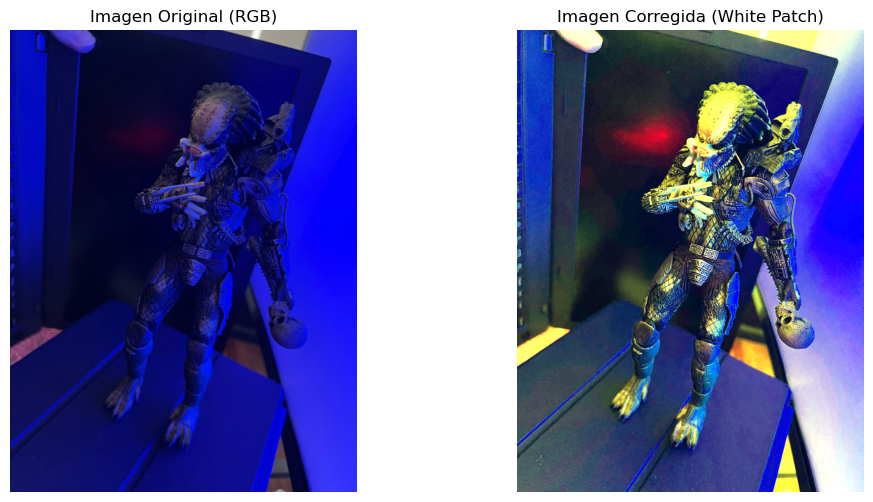

In [34]:
process_image('data/tp1/wp_blue.png', percentile=95)

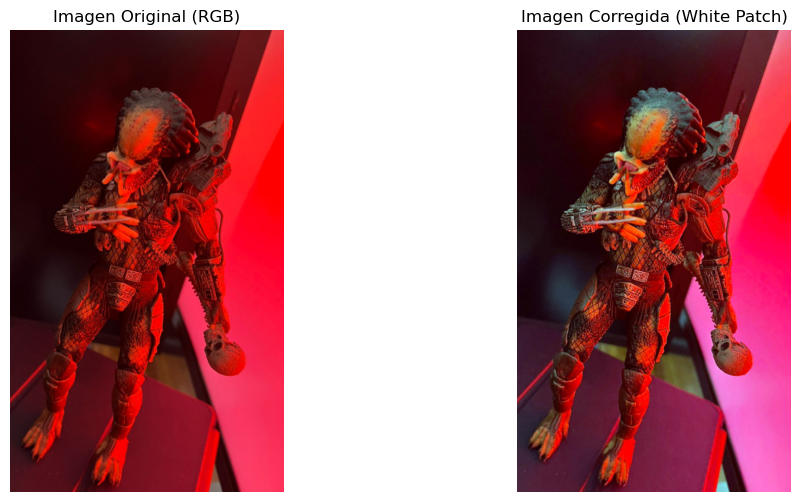

In [38]:
process_image('data/tp1/wp_red.png', percentile=90)

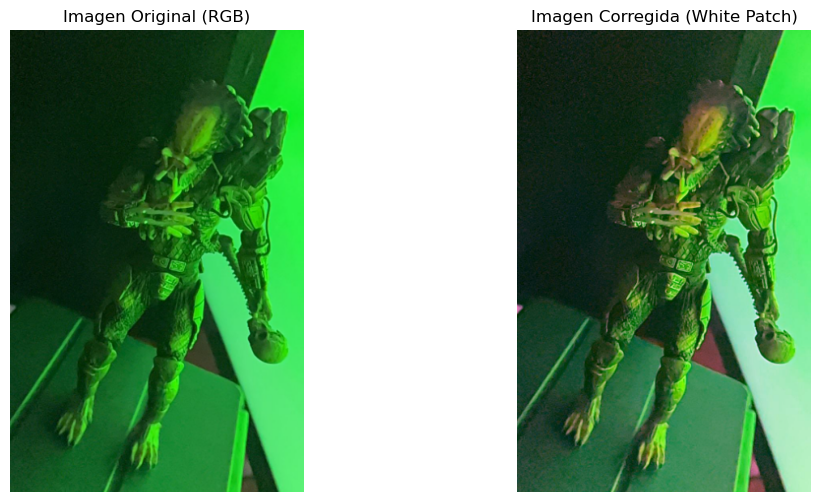

In [36]:
process_image('data/tp1/wp_green.png', percentile=95)

#### Análisis de resultados de White Patch


Al procesar las imagenes con el algoritmo de white patch observamos que:

- **`wp_blue`:** la dominante azul se reduce, pero la corrección es excesiva, por lo que la figura queda amarillenta y la pared, casi blanca, pierde detalle.
- **`wp_red`:** la figura queda más neutra, pero la pared pasa de rojo a rosa.
- **`wp_green`:** baja el verde, pero la imagen queda apagada y la pared adquiere un tono menta.

En ninguno de los tres casos se recuperan colores naturales: la dominante se atenúa, pero no desaparece.

En qué falla el algoritmo para estas imágenes:

1. **El supuesto del blanco no se cumple.** No hay un objeto blanco, y lo más brillante es una pared teñida por la luz de color. El método la toma como si fuera blanca.
2. **Sensibilidad al máximo.** Unos pocos píxeles pueden fijar el valor maximo de cada canal. El percentil lo mejora, pero es una elección empírica.
3. **Corrección global.** Se aplica un solo factor por canal a toda la imagen, pero la iluminación no es uniforme. Por ejemplo: la pared recibe luz directa y la figura y el fondo mucho menos.

White Patch atenúa el color dominante pero no lo elimina en ninguna de las tres imágenes. Funciona mejor cuando hay un blanco real, la iluminación es pareja y no hay saturación. Con luces de color intensas y sin referencia blanca, el resultado depende de qué píxeles fijen el máximo.

# Parte 2
    
  1. Para las imágenes `img1_tp.png` y `img2_tp.png`, leerlas con OpenCV en escala de grises y visualizarlas.
  2. Elija el número de bins que crea conveniente y grafique su histograma, compare los histogramas entre sí. Explicar lo que se observa. Si tuviera que entrenar un modelo de clasificación/detección de imágenes, ¿considera que puede ser de utilidad tomar como ‘features’ a los histogramas?

In [46]:
import os
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

In [49]:
# leer imagenes en escala de grises
img1: ndarray = cv.imread(os.path.join(folder, 'img_1.png'), cv.IMREAD_GRAYSCALE)
img2: ndarray = cv.imread(os.path.join(folder, 'img_2.png'), cv.IMREAD_GRAYSCALE)

if img1 is None or img2 is None:
  raise FileNotFoundError('Error al cargar img_1.png o img_2.png')

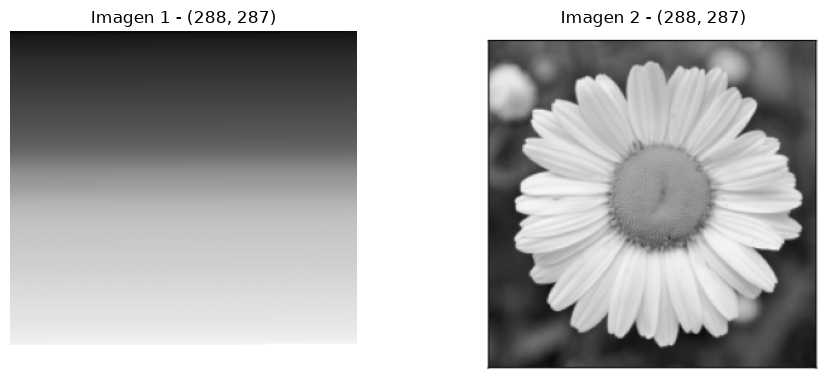

In [51]:
# visualizamos la imagenes 
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img1, cmap='gray', vmin=0, vmax=255)
plt.title(f'Imagen 1 - {img1.shape}')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img2, cmap='gray', vmin=0, vmax=255)
plt.title(f'Imagen 2 - {img2.shape}')
plt.axis('off')

plt.tight_layout()
plt.show()

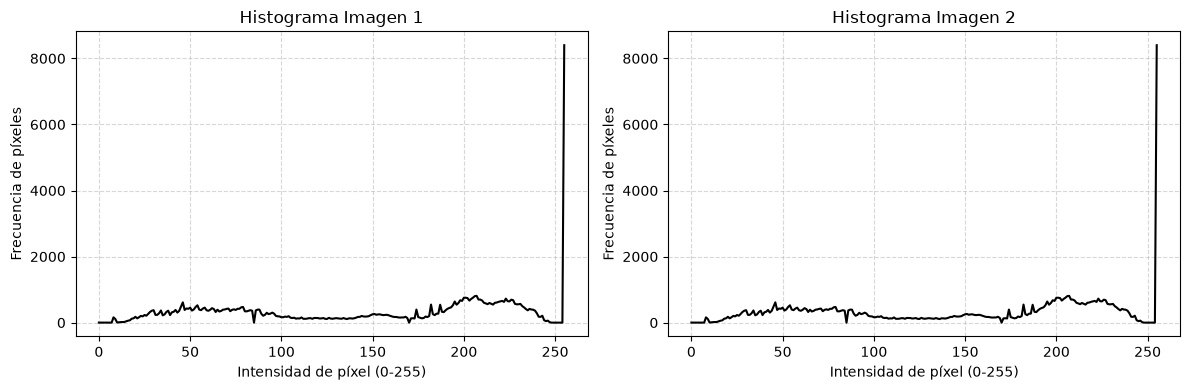

In [52]:
bins = 256 # elegimos 256 bins para cubrir de forma exacta todos los niveles de intensidad de la imagen (0 a 255)

plt.figure(figsize=(12, 4))

# Histograma de Imagen 1
hist1, _ = np.histogram(img1.ravel(), bins, )
plt.subplot(1, 2, 1)
plt.plot(hist1, color='black')
plt.title('Histograma Imagen 1')
plt.xlabel('Intensidad de píxel (0-255)')
plt.ylabel('Frecuencia de píxeles')
plt.xlim()
plt.grid(True, linestyle='--', alpha=0.5)

# Histograma de Imagen 2
hist2, _ = np.histogram(img2.ravel(), bins, )
plt.subplot(1, 2, 2)
plt.plot(hist2, color='black')
plt.title('Histograma Imagen 2')
plt.xlabel('Intensidad de píxel (0-255)')
plt.ylabel('Frecuencia de píxeles')
plt.xlim()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

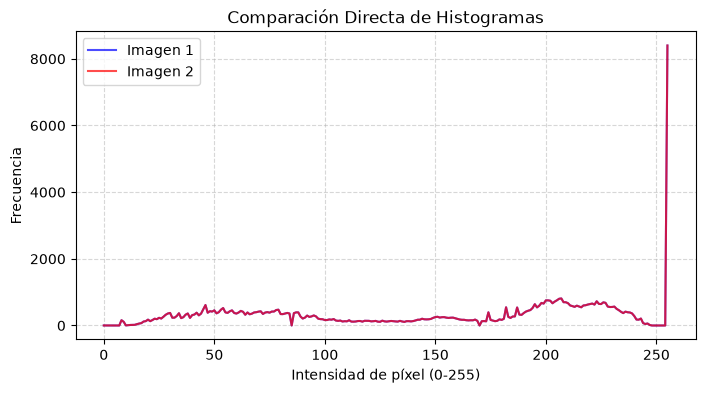

In [53]:
plt.figure(figsize=(8, 4))
plt.plot(hist1, label='Imagen 1', color='blue', alpha=0.7)
plt.plot(hist2, label='Imagen 2', color='red', alpha=0.7)
plt.title('Comparación Directa de Histogramas')
plt.xlabel('Intensidad de píxel (0-255)')
plt.ylabel('Frecuencia')
plt.xlim()
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


Al comparar visualmente las imágenes y sus correspondientes histogramas, se evidencia un claro contraste entre la información espacial y la estadística:
* **Contenido Visual**: La **Imagen 1** consiste en un gradiente continuo de tonos de gris, mientras que la **Imagen 2** representa la fotografía de una flor.
* **Comportamiento del Histograma**: A pesar de tratarse de estructuras visuales y semánticas totalmente distintas, sus histogramas de frecuencia de intensidad son **100% idénticos**, solapándose a la perfección en la comparación directa.

Este fenómeno se explica por la naturaleza matemática del histograma:
* El histograma es una distribución puramente estadística que contabiliza únicamente la **frecuencia de ocurrencia** de cada nivel de intensidad (de 0 a 255).
* Al calcularlo, se produce una **pérdida total de la información espacial**: se pierde la ubicación geométrica de cada píxel dentro de la matriz de la imagen. Por lo tanto, cualquier reordenamiento o disposición distinta de los mismos píxeles generará exactamente la misma curva.

Debido a esto, si entrenáramos un modelo utilizando únicamente el histograma como vector de características (features), el algoritmo sería totalmente incapaz de distinguir entre un gradiente abstracto y una flor. Por lo tanto, **el histograma por sí solo no es un descriptor suficiente para tareas de reconocimiento o detección de objetos complejos**.